# 03 · Outliers de registros y dataset preliminar

In [1]:
import json
import sys
from datetime import datetime
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / 'src' / 'config.py').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, estilo
from src.db import consultar, hash_sql
from src.eda_tablas import agregar_porcentaje, nombre_etapa
from src.episodios import (
    COLUMNAS_FECHA,
    COLUMNAS_VISITA,
    construir_episodios,
    contar_los_recortados,
    episodio_de_visitas,
    preparar_visitas,
    resumen_sensibilidad,
    valores_comparables,
)
from src.estilo import fmt_decimal, fmt_entero, fmt_pct
from src.graficos import (
    COLOR_HOSP,
    COLORES_GRUPO,
    ETIQUETAS_CORTAS_GRUPO,
    activar_formato_tablas,
    ancho_linea,
    aplicar_estilo,
    etiquetas_directas,
    formato_eje_anios,
    guardar_figura,
    leyenda_fuera,
    linea_con_ocultos,
    linea_umbral,
    titulo_hallazgo,
)
from src.limpieza import (
    aplicar_reglas_registro,
    conteo_por_paciente_anio,
    detectar_registros,
    resumen_recorridos_identicos,
    resumen_marcas,
)
from src.privacidad import enmascarar_pequenos, suprimir_pequenos, tabla_segura
from src.tablas import mostrar_tabla, tabla_medidas

aplicar_estilo()
activar_formato_tablas()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

G1, G2, G3 = config.GRUPOS
VERDE = estilo.VERDE
NOMBRE_CRITERIO = {'p99': 'percentil 99', 'p99_9': 'percentil 99,9', 'tukey_log': 'Tukey sobre el logaritmo'}
TIPOS_CON_DURACION = (config.CONCEPTO_URGENCIAS, config.CONCEPTO_SEGMENTO, config.CONCEPTO_PISO)


def nombre_etapa_sql(etapa):
    """Etiqueta de las filas de 03_detail_duracion_extrema (código de etapa o «todas»)."""
    return 'Todas las etapas' if str(etapa) == 'todas' else nombre_etapa(int(etapa))


def marcar_corte(ax):
    """Línea vertical en FECHA_CORTE_ANALISIS (población de análisis)."""
    linea_umbral(ax, config.FECHA_CORTE_ANALISIS, 'Corte del análisis', destacada=False)


def columnas_caso(clave):
    """Columnas de marca de un caso: una, o una por criterio de detección."""
    return [c for c in marcas.columns if c == clave or c.startswith(f'{clave}__')]


def mostrar_afectados(clave):
    """Visitas de urgencias afectadas por un caso (n y %), una fila por criterio."""
    tabla = resumen_marcas(marcas[columnas_caso(clave)])
    mostrar_tabla(tabla_segura(tabla), f"{config.REGLAS_REGISTRO[clave]['descripcion']}: visitas de urgencias afectadas")


def mostrar_accion(clave):
    """Acción de la regla leída de REGLAS_REGISTRO (y su criterio, si tiene varios)."""
    regla = config.REGLAS_REGISTRO[clave]
    fila = {'caso': regla['descripcion'], 'accion': regla['accion']}
    if 'criterios' in regla:
        fila['criterio'] = regla.get('criterio', 'pendiente')
    mostrar_tabla(pd.DataFrame([fila]), f"{regla['descripcion']}: acción")


def grafico_mensual(clave, nombre_figura):
    """Tabla y gráfico del % de visitas de urgencias del mes marcadas por un caso."""
    descripcion = config.REGLAS_REGISTRO[clave]['descripcion']
    marca = marcas[columnas_caso(clave)[0]]
    mes = visitas['llegada'].dt.to_period('M').dt.to_timestamp()
    tabla = pd.DataFrame({'n': mes.value_counts(), 'n_afectadas': mes[marca].value_counts()}).fillna(0).astype('int64')
    tabla = tabla.sort_index().rename_axis('mes')
    tabla['pct_afectadas'] = 100 * tabla['n_afectadas'] / tabla['n']
    mostrar_tabla(tabla_segura(tabla, conservar_ceros=True), f'{descripcion}: visitas afectadas por mes de llegada')
    fig, ax = plt.subplots(figsize=(13, 5.5))
    linea_con_ocultos(ax, tabla.index, tabla['pct_afectadas'], tabla['n_afectadas'], VERDE, 'Visitas afectadas (%)')
    marcar_corte(ax)
    ax.set_ylabel('% de visitas del mes')
    titulo_hallazgo(fig, f'{descripcion} por mes de llegada', '% de visitas de urgencias del mes marcadas por la regla')
    guardar_figura(fig, nombre_figura)
    plt.show()


def grafico_conteos(conteos, limites_criterio, titulo, subtitulo, nombre_figura, etiqueta_x, anios=False):
    """Tabla y barras de frecuencias agregadas (una barra por valor), en escala log, con los límites."""
    conteos = conteos.sort_index()
    mostrar_tabla(suprimir_pequenos(conteos.rename('n').to_frame(), ['n']), titulo)
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.bar(conteos.index, enmascarar_pequenos(conteos, conteos), width=0.8, color=VERDE)
    ax.set_yscale('log')
    for i, (criterio, limite) in enumerate((limites_criterio or {}).items()):
        linea_umbral(ax, limite, f'{NOMBRE_CRITERIO[criterio].capitalize()}: {fmt_decimal(limite, 1)}',
                     destacada=False, fila=i)
    if anios:
        formato_eje_anios(ax.xaxis)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel('Frecuencia (escala log)')
    titulo_hallazgo(fig, titulo, subtitulo)
    guardar_figura(fig, nombre_figura)
    plt.show()

## 1. Datos
### 1.1 Extracción de visitas de urgencias

`visitas_urgencias.sql` devuelve una fila por visita 9203, incluidas las que no tienen etapas. Se verifica que el concepto de la nota de consulta exista y que la extracción tenga las columnas y tipos esperados; solo se muestra un aviso si algo falla.

In [2]:
conceptos_nota = consultar('02_concepto_nota_consulta')
if conceptos_nota.empty:
    tabla_medidas({'aviso': "No hay conceptos con el nombre 'Emergency department Consult note': "
                            'nota_consulta_urg será siempre False.'}, 'Aviso: concepto de la nota de consulta')

visitas_crudas = consultar('visitas_urgencias')
columnas_faltantes = [c for c in COLUMNAS_VISITA if c not in visitas_crudas.columns]
fechas_no_fecha = [c for c in COLUMNAS_FECHA
                   if c in visitas_crudas.columns and not pd.api.types.is_datetime64_any_dtype(visitas_crudas[c])]
if columnas_faltantes or fechas_no_fecha:
    tabla_medidas({
        'columnas que faltan': ', '.join(columnas_faltantes) or '—',
        'columnas de fecha con otro tipo de dato': ', '.join(fechas_no_fecha) or '—',
    }, 'Aviso: extracción de visitas')

### 1.2 Preparación de las visitas

`preparar_visitas` ajusta tipos, rellena los fines de las visitas sin etapas y calcula la edad al llegar con la regla del notebook 02.

In [3]:
visitas = preparar_visitas(visitas_crudas)
del visitas_crudas

### 1.3 Episodio de cada visita

Se asigna a cada visita su episodio con la fusión de 60 minutos, para contar cuántos episodios quita cada regla que excluye visitas.

In [4]:
episodio_visita = episodio_de_visitas(visitas, config.UMBRAL_FUSION_MIN)

### 1.4 Marcas de cada caso

Se calculan los límites de detección y las marcas de cada caso. Los límites de duración de las etapas se calculan en SQL para cada tipo de etapa no previa (9203, 3045729 y 9201); los demás, sobre las visitas.

In [5]:
duracion_sql = consultar('03_detail_duracion_extrema')
duracion_sql['etapa'] = duracion_sql['etapa'].map(nombre_etapa_sql)
duracion_sql = duracion_sql.set_index('etapa')
duracion_por_tipo = duracion_sql.drop(index='Todas las etapas', errors='ignore')
limites_etapa = {}
for concepto in TIPOS_CON_DURACION:
    if nombre_etapa(concepto) in duracion_por_tipo.index:
        fila = duracion_por_tipo.loc[nombre_etapa(concepto)]
        limites_etapa[concepto] = {'p99_9': float(fila['p99_9_h']), 'tukey_log': float(fila['tukey_log_h'])}

recorridos = consultar('03_recorridos_identicos_marcas')
marcas, limites_usados = detectar_registros(visitas, limites_etapa, recorridos=recorridos)

## 2. Año de nacimiento imposible
### Detección

`year_of_birth < 1900` (incluye el año 1). Se cuenta en personas (SQL agregado sobre `person`) y en visitas de urgencias.

In [6]:
casos_person = consultar('03_person_casos')
anios = casos_person[casos_person['caso'] == 'anio_nacimiento'].set_index('categoria').drop(columns='caso')
anios.index = [c.split(' ', 1)[1] for c in anios.index]
mostrar_tabla(tabla_segura(anios.rename_axis('año de nacimiento'), conservar_ceros=True),
              'Personas y visitas de urgencias por año de nacimiento')

**Personas y visitas de urgencias por año de nacimiento**

,n_personas,n_personas_con_urgencias,n_visitas_urgencias
año de nacimiento,,,
año 1,85,12,21
entre 2 y 1899,<10,0,0
desde 1900,912.118,231.071,598.067


### Registros afectados

In [7]:
mostrar_afectados('anio_nacimiento_imposible')

**Año de nacimiento imposible: visitas de urgencias afectadas**

,n,n_afectados,pct_afectados
marca,,,
anio_nacimiento_imposible,598.088,21,"0,0"


### Distribución

**Año de nacimiento de las visitas afectadas**

,n
year_of_birth,
1,21


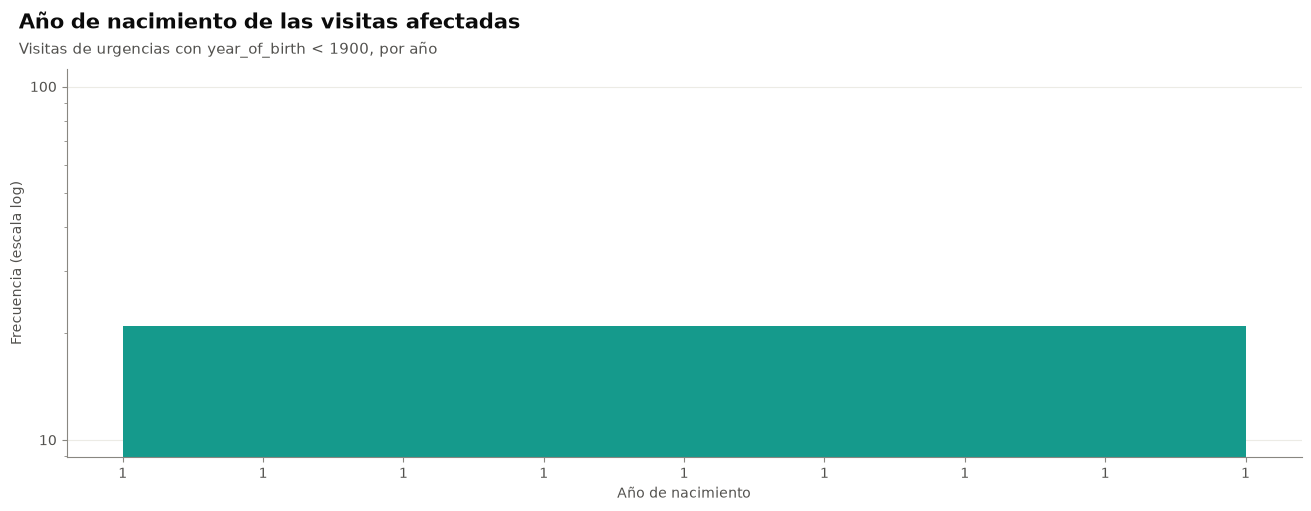

In [8]:
grafico_conteos(visitas.loc[marcas['anio_nacimiento_imposible'], 'year_of_birth'].value_counts(), None,
                'Año de nacimiento de las visitas afectadas', 'Visitas de urgencias con year_of_birth < 1900, por año',
                '03_anio_nacimiento_imposible', 'Año de nacimiento', anios=True)

## 3. Edad negativa o mayor a 110
### Detección

Edad = año de llegada − `year_of_birth`, con `year_of_birth ≥ 1900`. Dos reglas: edad negativa y edad mayor a 110 (esta se conserva como edad válida).

### Registros afectados

In [9]:
mostrar_afectados('edad_negativa')
mostrar_afectados('edad_mayor_110')

**Edad negativa: visitas de urgencias afectadas**

,n,n_afectados,pct_afectados
marca,,,
edad_negativa,598.088,<10,suprimido


**Edad mayor a 110: visitas de urgencias afectadas**

,n,n_afectados,pct_afectados
marca,,,
edad_mayor_110,598.088,<10,suprimido


### Distribución

**Edad al llegar de las visitas afectadas**

,n
-2,<10
114,<10


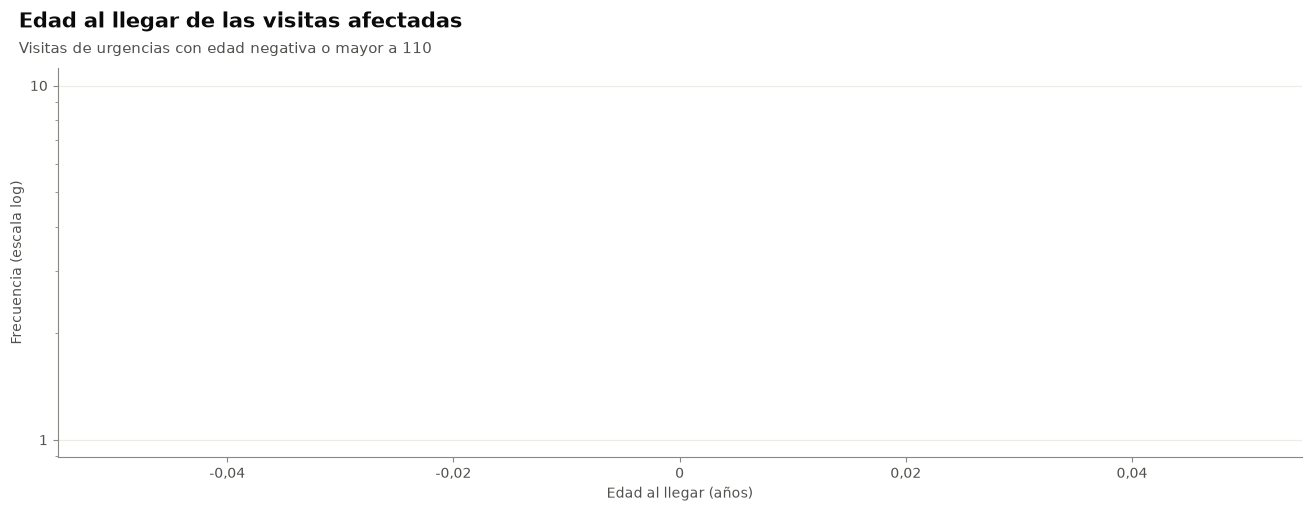

In [10]:
edad_bruta = visitas['llegada'].dt.year - visitas['year_of_birth']
grafico_conteos(edad_bruta[marcas['edad_negativa'] | marcas['edad_mayor_110']].value_counts(), None,
                'Edad al llegar de las visitas afectadas', 'Visitas de urgencias con edad negativa o mayor a 110',
                '03_edad_negativa_o_mayor_110', 'Edad al llegar (años)')

## 4. Sexo sin dato
### Detección

En `person`, `gender_concept_id = 0` (SQL agregado). En las visitas, sexo distinto de FEMALE y MALE (concepto 0 o sin traducción).

In [11]:
sexo = casos_person[casos_person['caso'] == 'sexo'].set_index('categoria').drop(columns='caso')
sexo.index = [c.split(' ', 1)[1] for c in sexo.index]
mostrar_tabla(tabla_segura(sexo.rename_axis('gender_concept_id'), conservar_ceros=True),
              'Personas y visitas de urgencias según gender_concept_id')

**Personas y visitas de urgencias según gender_concept_id**

,n_personas,n_personas_con_urgencias,n_visitas_urgencias
gender_concept_id,,,
con concepto,912.076,231.029,597.960
concepto 0,129,54,128


### Registros afectados

In [12]:
mostrar_afectados('sexo_sin_dato')

**Sexo sin dato: visitas de urgencias afectadas**

,n,n_afectados,pct_afectados
marca,,,
sexo_sin_dato,598.088,128,"0,0"


### Distribución

**Sexo sin dato: visitas afectadas por mes de llegada**

,n,n_afectadas,pct_afectadas
mes,,,
2023-01-01,16.734,<10,suprimido
2023-02-01,14.802,0,"0,0"
2023-03-01,17.256,0,"0,0"
2023-04-01,16.066,<10,suprimido
2023-05-01,18.302,<10,suprimido
2023-06-01,16.599,0,"0,0"
2023-07-01,16.300,0,"0,0"
2023-08-01,16.231,0,"0,0"
2023-09-01,15.068,0,"0,0"


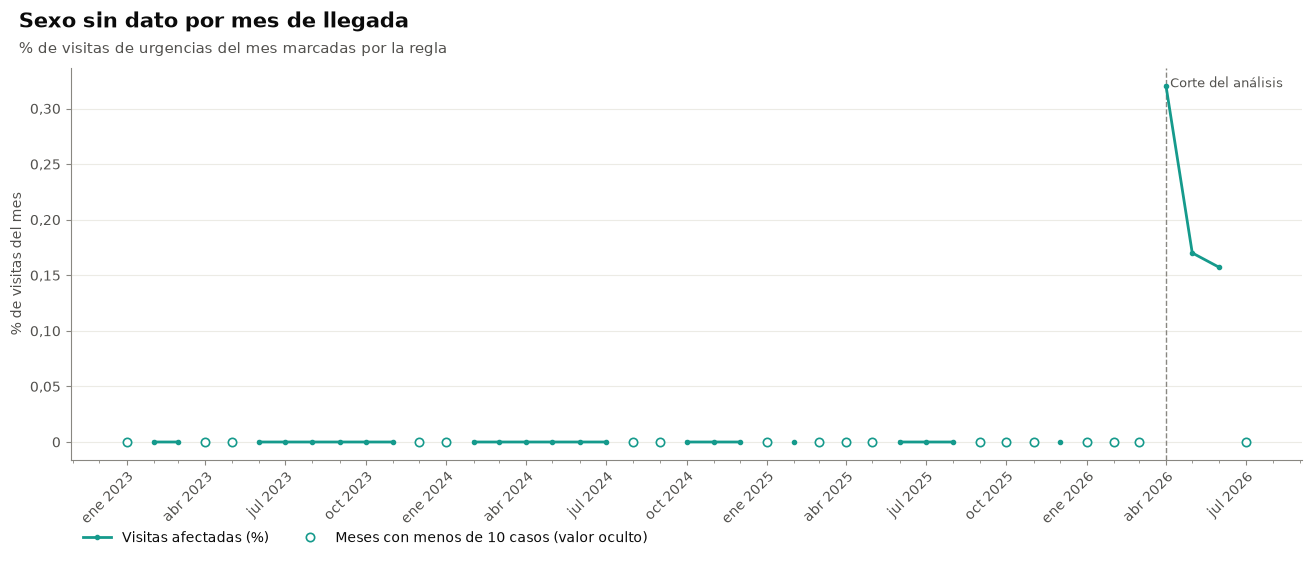

In [13]:
grafico_mensual('sexo_sin_dato', '03_sexo_sin_dato_mes')

## 5. Etapas de duración 0
### Detección

Etapas no previas con fin igual al inicio, por tipo de etapa (SQL agregado). Una visita queda marcada si tiene al menos una.

In [14]:
cero = duracion_sql[['n', 'n_dur_0']].copy()
cero['pct_dur_0'] = 100 * cero['n_dur_0'] / cero['n']
mostrar_tabla(tabla_segura(cero, conservar_ceros=True), 'Etapas no previas con duración 0, por tipo de etapa')

**Etapas no previas con duración 0, por tipo de etapa**

,n,n_dur_0,pct_dur_0
etapa,,,
Movimiento o etapa (3045729),736.845,273.864,"37,2"
Ingreso ambulatorio (581479),47,47,"100,0"
Hospitalización en piso (9201),63.514,17,"0,0"
Ingreso por urgencias (9203),386.518,88.969,"23,0"
Todas las etapas,1.186.924,362.897,"30,6"


### Registros afectados

In [15]:
mostrar_afectados('etapas_duracion_0')

**Etapas de duración 0: visitas de urgencias afectadas**

,n,n_afectados,pct_afectados
marca,,,
etapas_duracion_0,598.088,362.845,"60,7"


### Distribución

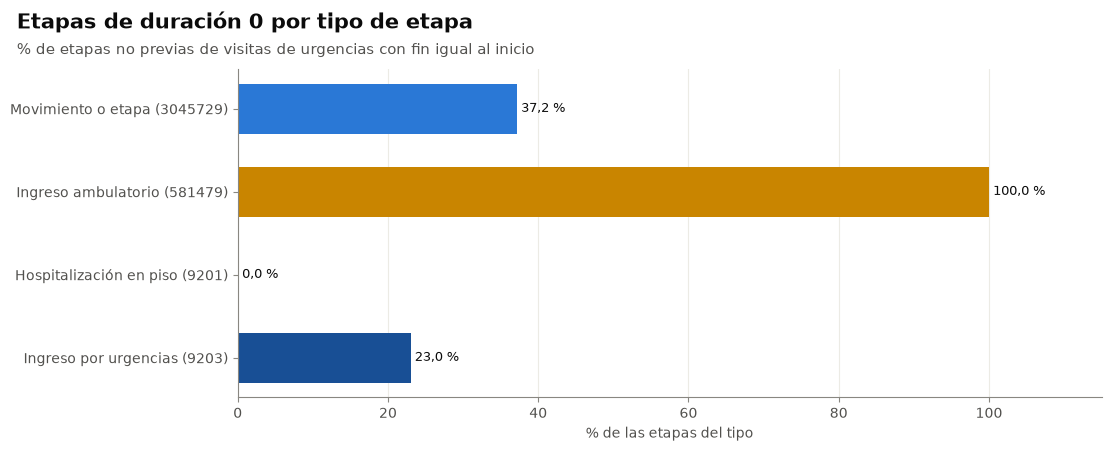

**Etapas de duración 0: visitas afectadas por mes de llegada**

,n,n_afectadas,pct_afectadas
mes,,,
2023-01-01,16.734,11.295,"67,5"
2023-02-01,14.802,9.942,"67,2"
2023-03-01,17.256,11.470,"66,5"
2023-04-01,16.066,10.592,"65,9"
2023-05-01,18.302,12.620,"69,0"
2023-06-01,16.599,11.315,"68,2"
2023-07-01,16.300,10.845,"66,5"
2023-08-01,16.231,10.685,"65,8"
2023-09-01,15.068,9.856,"65,4"


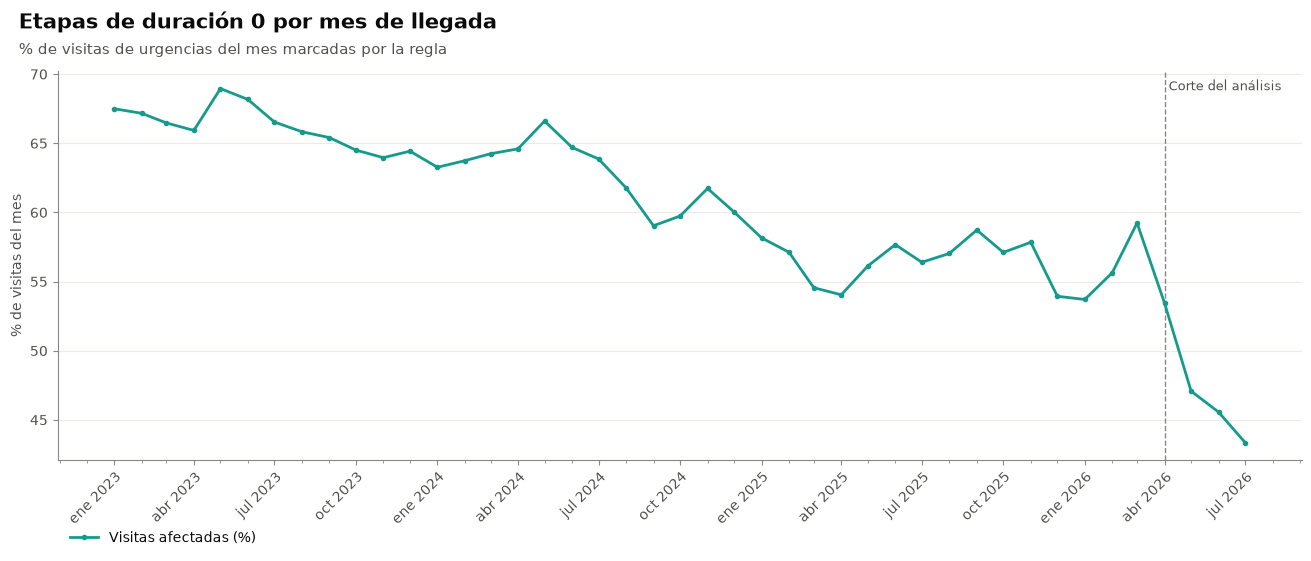

In [16]:
por_tipo = cero.drop(index='Todas las etapas')
colores = [estilo.COLOR_ETAPA.get(int(e.rsplit('(', 1)[1].rstrip(')')), estilo.GRISES[1]) if '(' in e else estilo.GRISES[1]
           for e in por_tipo.index]
fig, ax = plt.subplots(figsize=(11, 0.6 * len(por_tipo) + 2))
y = np.arange(len(por_tipo))[::-1]
valores = por_tipo['pct_dur_0'].where(por_tipo['n_dur_0'] >= config.MIN_CELDA)
ax.barh(y, valores.fillna(0), height=0.6, color=colores)
for yi, valor in zip(y, valores):
    ax.annotate(fmt_pct(valor) if pd.notna(valor) else f'<{config.MIN_CELDA}', xy=(0 if pd.isna(valor) else valor, yi),
                xytext=(3, 0), textcoords='offset points', va='center', fontsize=estilo.TAMANO_MINIMO)
ax.set_yticks(y, por_tipo.index)
ax.set_xlim(0, max(1, valores.max(skipna=True) if valores.notna().any() else 1) * 1.15)
ax.grid(False)
ax.grid(axis='x')
ax.set_xlabel('% de las etapas del tipo')
titulo_hallazgo(fig, 'Etapas de duración 0 por tipo de etapa', '% de etapas no previas de visitas de urgencias con fin igual al inicio')
guardar_figura(fig, '03_etapas_duracion_0')
plt.show()

grafico_mensual('etapas_duracion_0', '03_etapas_duracion_0_mes')

## 6. Etapas de duración extrema
### Detección

Por tipo de etapa no previa (9203, 3045729 y 9201): duración por encima del percentil 99,9 y por encima del límite de Tukey sobre el logaritmo (`exp(Q3 + 3 × RIC)` con los cuartiles del logaritmo de las duraciones positivas de ese tipo). Una visita queda marcada si la duración máxima de alguno de sus tipos de etapa supera el límite de ese tipo.

In [17]:
columnas = ['n_positivas', 'p50_h', 'p99_h', 'p99_9_h', 'tukey_log_h', 'max_h', 'n_sobre_p99_9', 'n_sobre_tukey_log']
mostrar_tabla(tabla_segura(duracion_por_tipo[columnas], conservar_ceros=True),
              'Duración de las etapas no previas por tipo (horas): límites y etapas que los superan')

**Duración de las etapas no previas por tipo (horas): límites y etapas que los superan**

,n_positivas,p50_h,p99_h,p99_9_h,tukey_log_h,max_h,n_sobre_p99_9,n_sobre_tukey_log
etapa,,,,,,,,
Movimiento o etapa (3045729),462.981,"3,50","103,96","374,57","1.218,45","2.236,94",462,20
Ingreso ambulatorio (581479),0,NaN,NaN,NaN,NaN,0,0,0
Hospitalización en piso (9201),63.497,"46,11","523,39","973,08","8.563,29","2.160,17",63,0
Ingreso por urgencias (9203),297.549,"0,06","0,21","257,40","0,37","20.730,34",298,1.087


### Registros afectados

Visitas marcadas con cada criterio, lado a lado.

In [18]:
mostrar_afectados('etapas_duracion_extrema')

**Etapas de duración extrema: visitas de urgencias afectadas**

,n,n_afectados,pct_afectados
marca,,,
etapas_duracion_extrema__p99_9,598.088,468,"0,1"
etapas_duracion_extrema__tukey_log,598.088,834,"0,1"


### Distribución

Histograma de la duración de cada tipo de etapa (incluidos los eventos previos), con los límites de su tipo calculados sobre las etapas no previas.

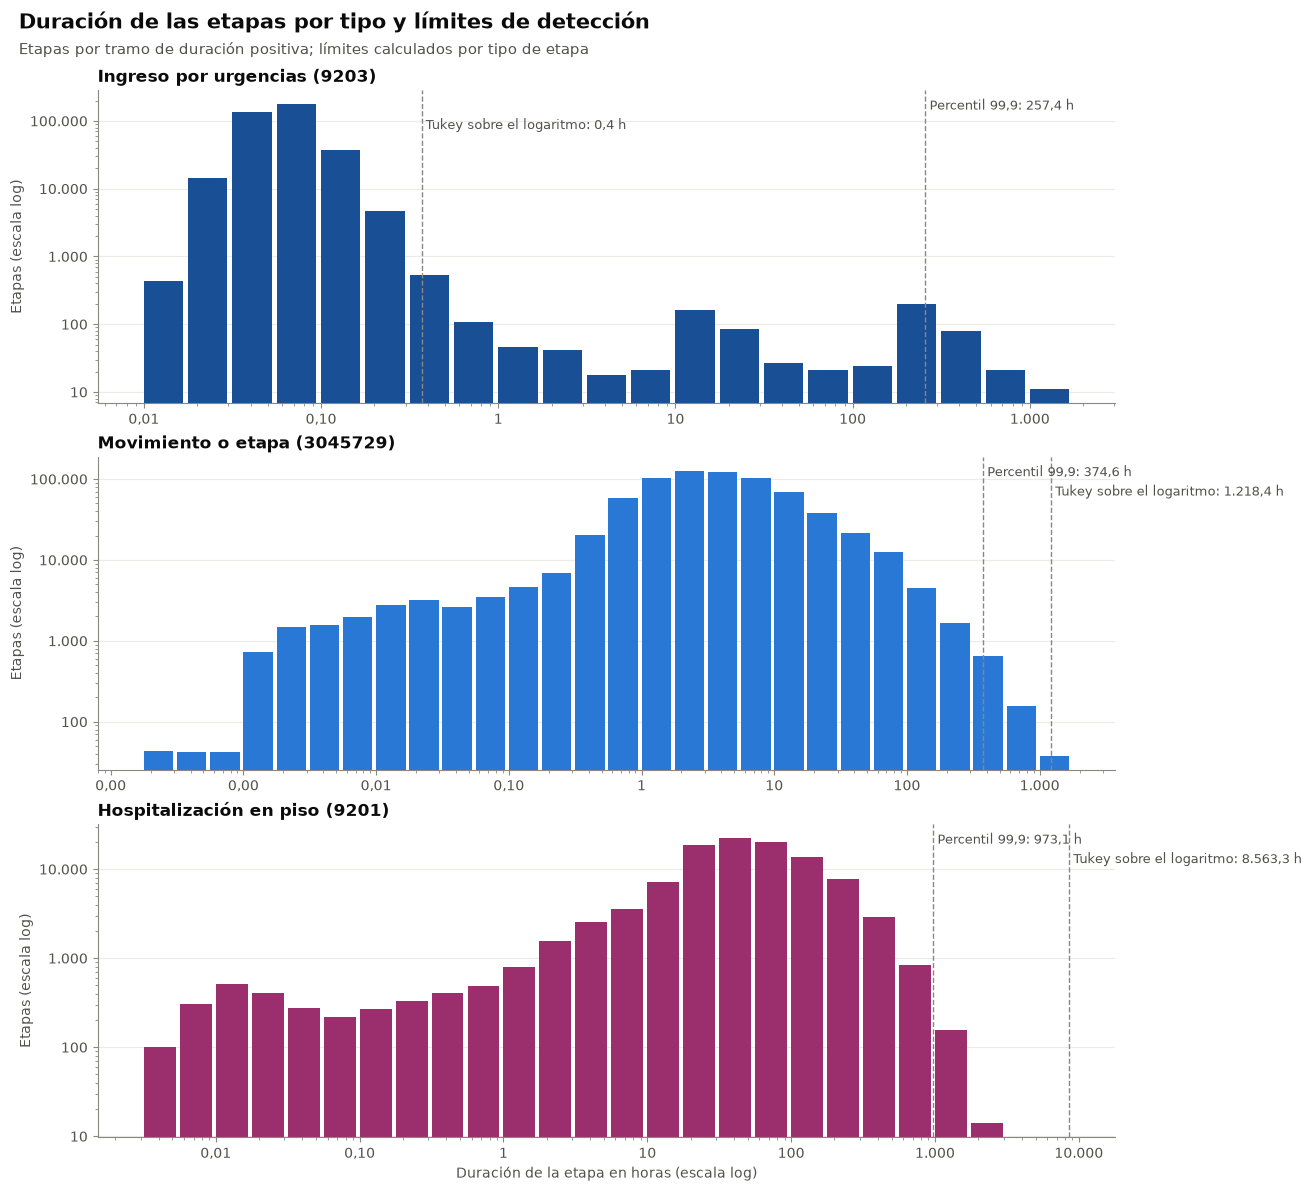

In [19]:
histograma = consultar('01_histograma_duracion_etapas')
histograma['bin_log10_h'] = histograma['bin_log10_h'].astype(float)
tipos = [c for c in TIPOS_CON_DURACION if c in limites_etapa]
fig, ejes = plt.subplots(len(tipos), 1, figsize=(13, 3.6 * len(tipos) + 1), squeeze=False)
for ax, concepto in zip(ejes[:, 0], tipos):
    por_bin = histograma[histograma['concepto_etapa'] == concepto].set_index('bin_log10_h')['n_detalles'].sort_index()
    centro = 10 ** (por_bin.index + 0.125)
    ax.bar(centro, enmascarar_pequenos(por_bin, por_bin), width=centro * 0.5,
           color=estilo.COLOR_ETAPA.get(concepto, VERDE))
    ax.set_xscale('log')
    ax.set_yscale('log')
    for i, (criterio, limite) in enumerate(limites_etapa[concepto].items()):
        linea_umbral(ax, limite, f'{NOMBRE_CRITERIO[criterio].capitalize()}: {fmt_decimal(limite, 1)} h',
                     destacada=False, fila=i)
    ax.set_ylabel('Etapas (escala log)')
    ax.set_title(nombre_etapa(concepto))
ejes[-1, 0].set_xlabel('Duración de la etapa en horas (escala log)')
titulo_hallazgo(fig, 'Duración de las etapas por tipo y límites de detección',
                'Etapas por tramo de duración positiva; límites calculados por tipo de etapa')
guardar_figura(fig, '03_etapas_duracion_extrema')
plt.show()

### Ingresos por urgencias de duración larga

Perfil de los ingresos (etapas 9203 no previas) según su duración, e ingresos de más de 22 minutos y de más de 24 horas por trimestre de inicio.

In [20]:
perfil_ingresos = consultar('03_ingresos_9203_perfil')
perfil_ingresos['tramo'] = [t.split(' ', 1)[1] for t in perfil_ingresos['tramo']]
mostrar_tabla(tabla_segura(perfil_ingresos.set_index('tramo'), conservar_ceros=True),
              'Ingresos por urgencias según su duración')

ingresos_trimestre = consultar('03_ingresos_9203_trimestre')
ingresos_trimestre['trimestre'] = pd.to_datetime(ingresos_trimestre['trimestre'])
ingresos_trimestre.index = [f'T{t.quarter} {t.year}' for t in ingresos_trimestre['trimestre']]
mostrar_tabla(tabla_segura(ingresos_trimestre.drop(columns='trimestre').rename_axis('trimestre'), conservar_ceros=True),
              'Ingresos por urgencias por trimestre de inicio')

**Ingresos por urgencias según su duración**

,n,n_con_movimientos,pct_con_movimientos,n_con_piso,pct_con_piso,n_fin_igual_ultimo_mov,pct_fin_igual_ultimo_mov,n_fija_salida,pct_fija_salida,n_fin_igual_inicio_piso,pct_fin_igual_inicio_piso,n_fin_igual_fin_piso,pct_fin_igual_fin_piso,n_fin_fraccion,pct_fin_fraccion
tramo,,,,,,,,,,,,,,,
hasta 22 min,385.422,294.729,"76,5",28.474,"7,4",8.454,"2,2",238.384,"61,9",0,"0,0",0,"0,0",0,"0,0"
22 min a 24 h,674,372,"55,2",38,"5,6",36,"5,3",532,"78,9",0,"0,0",<10,suprimido,208,"30,9"
1 a 11 días,182,123,"67,6",33,"18,1",97,"53,3",171,"94,0",0,"0,0",32,"17,6",142,"78,0"
más de 11 días,240,171,"71,2",103,"42,9",171,"71,2",240,"100,0",0,"0,0",103,"42,9",238,"99,2"


**Ingresos por urgencias por trimestre de inicio**

,n,n_mas_22_min,n_mas_24_h
trimestre,,,
T1 2023,33.844,25,<10
T2 2023,35.159,37,11
T3 2023,32.479,49,14
T4 2023,28.377,14,<10
T1 2024,27.174,28,<10
T2 2024,29.937,32,<10
T3 2024,26.765,34,0
T4 2024,24.636,29,<10
T1 2025,24.856,12,0


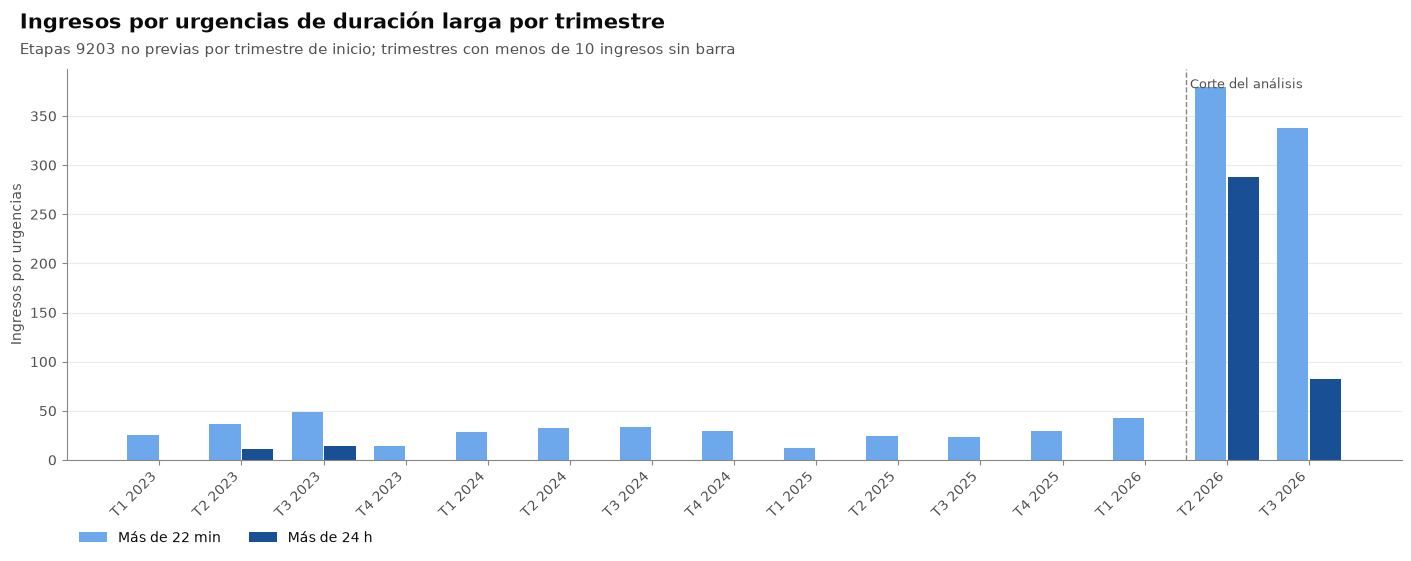

In [21]:
fig, ax = plt.subplots(figsize=(14, 5.5))
x = np.arange(len(ingresos_trimestre))
for j, (columna, etiqueta, color) in enumerate([
    ('n_mas_22_min', f'Más de {config.UMBRAL_INGRESO_LARGO_MIN} min', estilo.FAMILIAS['urgencias']['claro']),
    ('n_mas_24_h', f'Más de {config.UMBRAL_INGRESO_MUY_LARGO_H} h', estilo.FAMILIAS['urgencias']['oscuro']),
]):
    valores = enmascarar_pequenos(ingresos_trimestre[columna], ingresos_trimestre[columna])
    ax.bar(x + (j - 0.5) * 0.4, valores, width=0.38, color=color, label=etiqueta)
despues_del_corte = np.flatnonzero(ingresos_trimestre['trimestre'].to_numpy() > np.datetime64(config.FECHA_CORTE_ANALISIS))
if despues_del_corte.size:
    linea_umbral(ax, despues_del_corte[0] - 0.5, 'Corte del análisis', destacada=False)
ax.set_xticks(x, ingresos_trimestre.index, rotation=45, ha='right')
ax.set_ylabel('Ingresos por urgencias')
leyenda_fuera(ax, 'debajo', ncol=2)
titulo_hallazgo(fig, 'Ingresos por urgencias de duración larga por trimestre',
                'Etapas 9203 no previas por trimestre de inicio; trimestres con menos de 10 ingresos sin barra')
guardar_figura(fig, '03_ingresos_9203_trimestre')
plt.show()

#### Registros afectados

In [22]:
mostrar_afectados('ingresos_9203_largos')

**Ingresos por urgencias de duración larga: visitas de urgencias afectadas**

,n,n_afectados,pct_afectados
marca,,,
ingresos_9203_largos,598.088,843,"0,1"


## 7. Fines de etapa con fracción de segundo
### Detección

Fin de etapa con microsegundos distintos de 0, en etapas no previas de visitas de urgencias. Se muestra cuántos hay y si se concentran en pocos instantes repetidos.

In [23]:
fraccion = consultar('03_detail_fraccion_segundo')
fraccion.index = [nombre_etapa(c) for c in fraccion['concepto_etapa']]
fraccion = fraccion.drop(columns='concepto_etapa').rename_axis('etapa')
fraccion['pct_fraccion'] = 100 * fraccion['n_fraccion'] / fraccion['n']
mostrar_tabla(tabla_segura(fraccion, conservar_ceros=True), 'Etapas con fin con fracción de segundo, por tipo de etapa')

**Etapas con fin con fracción de segundo, por tipo de etapa**

,n,n_fraccion,pct_fraccion
etapa,,,
Hospitalización en piso (9201),63.514,397,"0,6"
Ingreso por urgencias (9203),386.518,588,"0,1"
Ingreso ambulatorio (581479),47,0,"0,0"
Movimiento o etapa (3045729),736.845,867,"0,1"


### Registros afectados

In [24]:
mostrar_afectados('fin_fraccion_segundo')

**Fines de etapa con fracción de segundo: visitas de urgencias afectadas**

,n,n_afectados,pct_afectados
marca,,,
fin_fraccion_segundo,598.088,507,"0,1"


### Distribución

Etapas que comparten el mismo instante de fin, para los 20 instantes más repetidos (sin mostrar el instante), y evolución mensual.

**Concentración en instantes repetidos**

,medida,valor
0,etapas con fracción de segundo,1.852
1,instantes distintos,2
2,% de las etapas en los 20 instantes más repetidos,"100,0 %"


**Etapas por instante, 20 instantes más repetidos**

,n_etapas
rango,
1,1.061
2,791


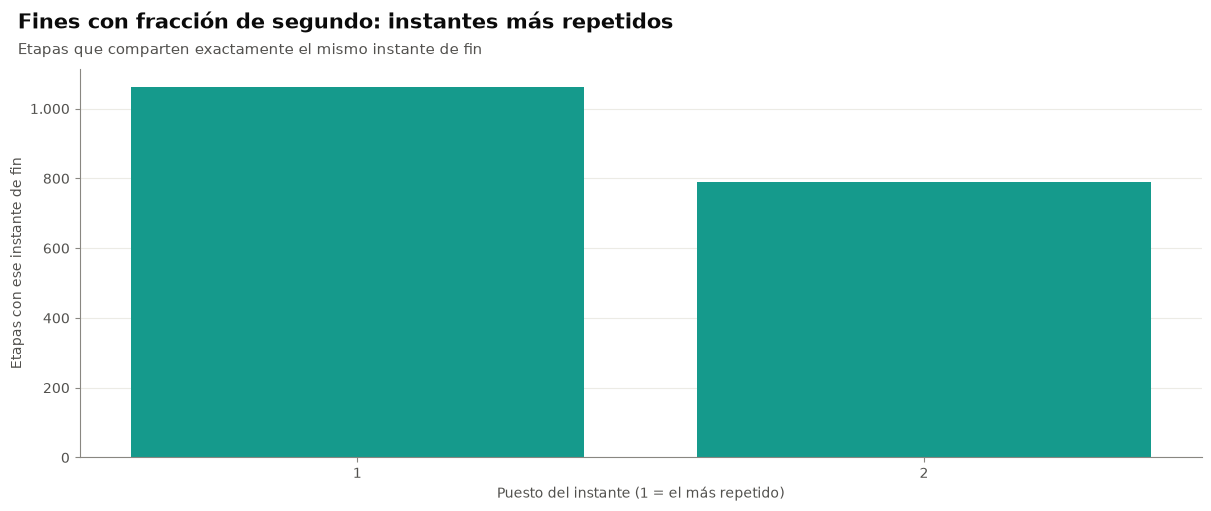

**Fines de etapa con fracción de segundo: visitas afectadas por mes de llegada**

,n,n_afectadas,pct_afectadas
mes,,,
2023-01-01,16.734,0,"0,0"
2023-02-01,14.802,0,"0,0"
2023-03-01,17.256,0,"0,0"
2023-04-01,16.066,0,"0,0"
2023-05-01,18.302,0,"0,0"
2023-06-01,16.599,0,"0,0"
2023-07-01,16.300,0,"0,0"
2023-08-01,16.231,0,"0,0"
2023-09-01,15.068,0,"0,0"


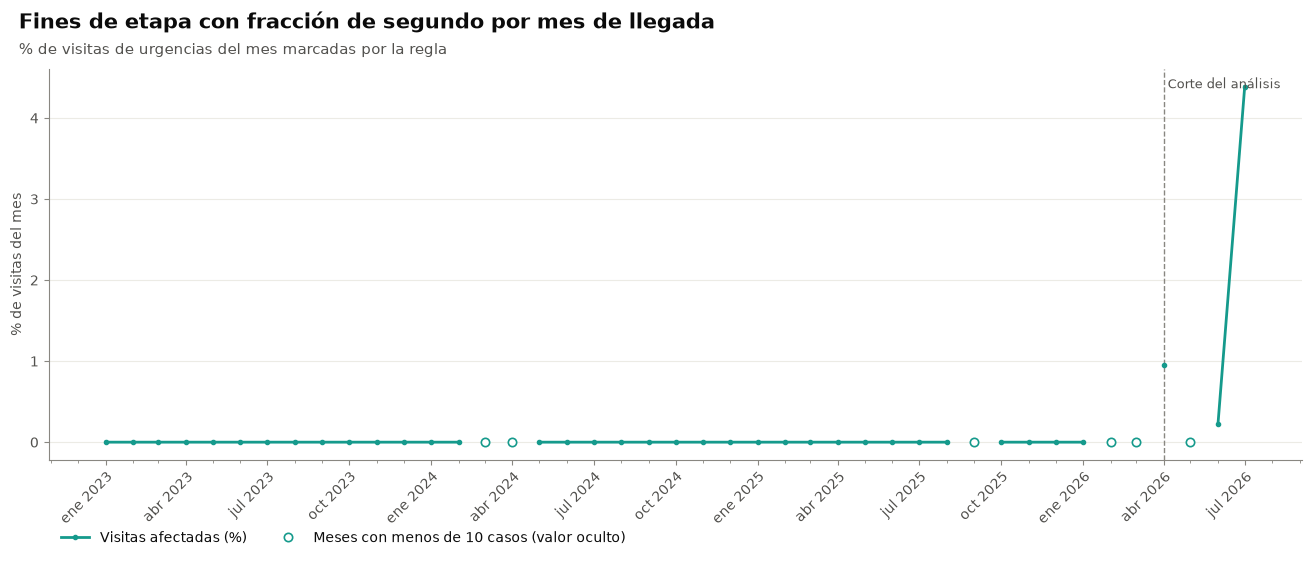

In [25]:
instantes = consultar('03_detail_fraccion_instantes')
if instantes.empty:
    tabla_medidas({'etapas con fracción de segundo': 0}, 'Instantes repetidos')
else:
    total = int(instantes['n_total'].iloc[0])
    tabla_medidas({
        'etapas con fracción de segundo': total,
        'instantes distintos': int(instantes['instantes_distintos'].iloc[0]),
        '% de las etapas en los 20 instantes más repetidos': fmt_pct(100 * instantes['n_etapas'].sum() / total),
    }, 'Concentración en instantes repetidos')
    por_rango = instantes.set_index('rango')['n_etapas']
    mostrar_tabla(suprimir_pequenos(por_rango.to_frame(), ['n_etapas']), 'Etapas por instante, 20 instantes más repetidos')
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.bar(por_rango.index, enmascarar_pequenos(por_rango, por_rango), color=VERDE)
    ax.set_xticks(list(por_rango.index))
    ax.set_xlabel('Puesto del instante (1 = el más repetido)')
    ax.set_ylabel('Etapas con ese instante de fin')
    titulo_hallazgo(fig, 'Fines con fracción de segundo: instantes más repetidos',
                    'Etapas que comparten exactamente el mismo instante de fin')
    guardar_figura(fig, '03_fin_fraccion_segundo_instantes')
    plt.show()

grafico_mensual('fin_fraccion_segundo', '03_fin_fraccion_segundo_mes')

## 8. Hospitalización que empieza antes de la llegada
### Detección

`inicio_piso < llegada`, dentro de la tolerancia de 1 h del evento previo. Con la regla del notebook 02, el LOS de estos episodios se recorta a 0.

### Registros afectados

In [26]:
mostrar_afectados('hosp_antes_de_llegada')

**Hospitalización que empieza antes de la llegada: visitas de urgencias afectadas**

,n,n_afectados,pct_afectados
marca,,,
hosp_antes_de_llegada,598.088,<10,suprimido


### Distribución

Minutos entre el inicio del piso y la llegada, en tramos de 5 minutos.

**Minutos entre el inicio del piso y la llegada**

,n_visitas
minutos antes de la llegada,
0–5 min,<10
5–10 min,<10
10–15 min,<10
15–20 min,<10
20–25 min,<10
25–30 min,<10
30–35 min,<10
35–40 min,<10
40–45 min,<10


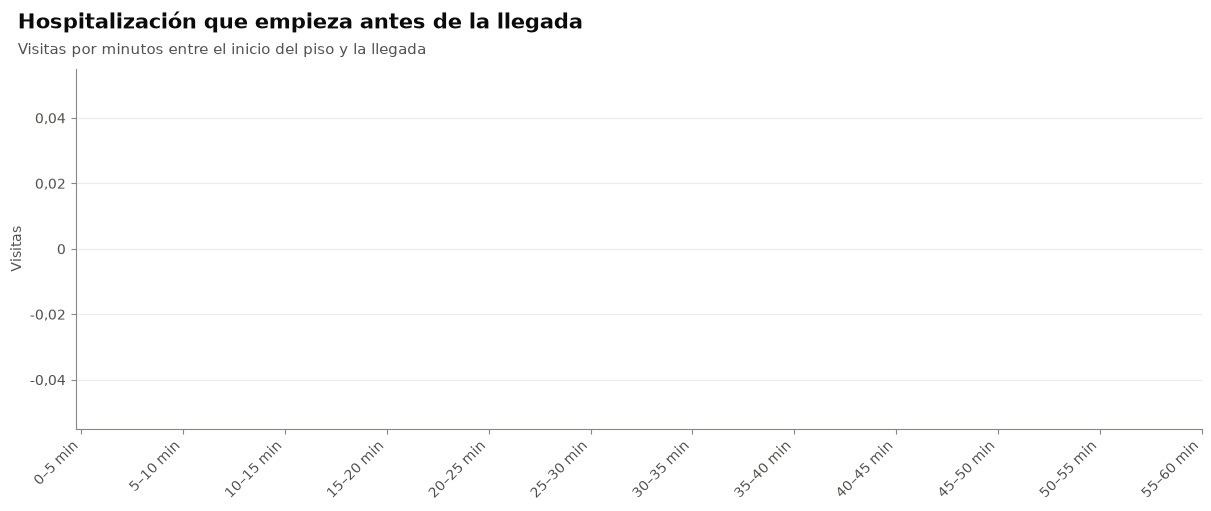

In [27]:
minutos = (visitas['llegada'] - visitas['inicio_piso']).dt.total_seconds() / 60
afectadas = minutos[marcas['hosp_antes_de_llegada']]
tramos = pd.cut(afectadas, bins=np.arange(0, 65, 5), right=True)
conteo_tramos = tramos.value_counts().sort_index()
conteo_tramos.index = [f'{int(i.left)}–{int(i.right)} min' for i in conteo_tramos.index]
mostrar_tabla(suprimir_pequenos(conteo_tramos.rename('n_visitas').rename_axis('minutos antes de la llegada').to_frame(),
                                ['n_visitas']), 'Minutos entre el inicio del piso y la llegada')
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(len(conteo_tramos)), enmascarar_pequenos(conteo_tramos, conteo_tramos), color=COLOR_HOSP)
ax.set_xticks(range(len(conteo_tramos)), conteo_tramos.index, rotation=45, ha='right')
ax.set_ylabel('Visitas')
titulo_hallazgo(fig, 'Hospitalización que empieza antes de la llegada', 'Visitas por minutos entre el inicio del piso y la llegada')
guardar_figura(fig, '03_hosp_antes_de_llegada')
plt.show()

## 9. Visitas sin etapas
### Detección

La visita no tiene etapas no previas. Con la regla del notebook 02 se incluyen con `fin = fin_urg = llegada` y quedan como contacto breve.

### Registros afectados

In [28]:
mostrar_afectados('visitas_sin_etapas')

**Visitas sin etapas: visitas de urgencias afectadas**

,n,n_afectados,pct_afectados
marca,,,
visitas_sin_etapas,598.088,54.440,"9,1"


### Distribución

**Visitas sin etapas: visitas afectadas por mes de llegada**

,n,n_afectadas,pct_afectadas
mes,,,
2023-01-01,16.734,1.404,"8,4"
2023-02-01,14.802,1.253,"8,5"
2023-03-01,17.256,1.444,"8,4"
2023-04-01,16.066,1.265,"7,9"
2023-05-01,18.302,1.595,"8,7"
2023-06-01,16.599,1.517,"9,1"
2023-07-01,16.300,1.328,"8,2"
2023-08-01,16.231,1.269,"7,8"
2023-09-01,15.068,1.270,"8,4"


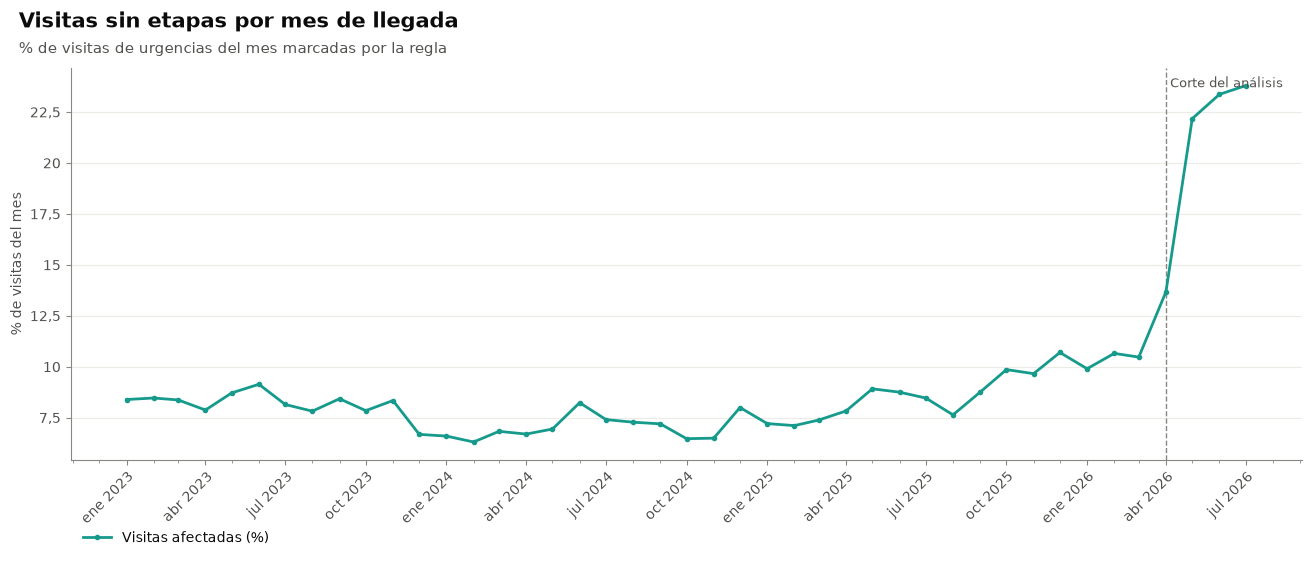

In [29]:
grafico_mensual('visitas_sin_etapas', '03_visitas_sin_etapas_mes')

## 10. Número extremo de etapas por visita
### Detección

`n_etapas` por encima del percentil 99,9 y por encima del límite de Tukey sobre el logaritmo, calculados sobre las visitas con al menos una etapa.

### Registros afectados

Visitas marcadas con cada criterio, lado a lado.

In [30]:
mostrar_afectados('etapas_por_visita_extremas')

**Número extremo de etapas por visita: visitas de urgencias afectadas**

,n,n_afectados,pct_afectados
marca,,,
etapas_por_visita_extremas__p99_9,598.088,275,"0,1"
etapas_por_visita_extremas__tukey_log,598.088,<10,suprimido


### Distribución

**Etapas por visita**

,n
n_etapas,
1,190.850
2,190.680
3,89.907
4,37.209
5,21.736
6,8.289
7,3.193
8,1.109
9,400


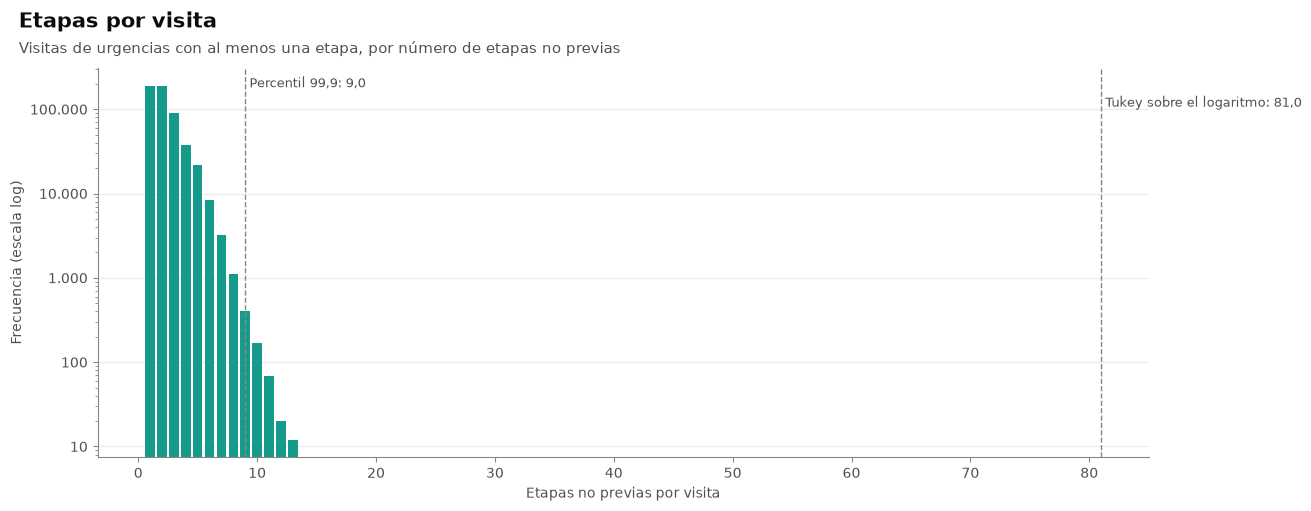

In [31]:
grafico_conteos(visitas.loc[visitas['n_etapas'] > 0, 'n_etapas'].value_counts(),
                limites_usados['etapas_por_visita_extremas'], 'Etapas por visita',
                'Visitas de urgencias con al menos una etapa, por número de etapas no previas',
                '03_etapas_por_visita', 'Etapas no previas por visita')

## 11. Pacientes con muchísimas visitas
### Detección

Visitas de urgencias del mismo paciente en el mismo año, por encima del percentil 99,9 y del límite de Tukey sobre el logaritmo. Se marcan todas las visitas de ese paciente en ese año.

### Registros afectados

Visitas marcadas con cada criterio, lado a lado.

In [32]:
mostrar_afectados('paciente_muchas_visitas')

**Pacientes con muchísimas visitas: visitas de urgencias afectadas**

,n,n_afectados,pct_afectados
marca,,,
paciente_muchas_visitas__p99_9,598.088,532,"0,1"
paciente_muchas_visitas__tukey_log,598.088,761,"0,1"


### Distribución

Pacientes-año según su número de visitas de urgencias en el año.

**Visitas de urgencias por paciente y año**

,n
llegada,
1,149.480
2,109.699
3,25.874
4,16.333
5,4.590
6,4.097
7,1.065
8,1.344
9,322


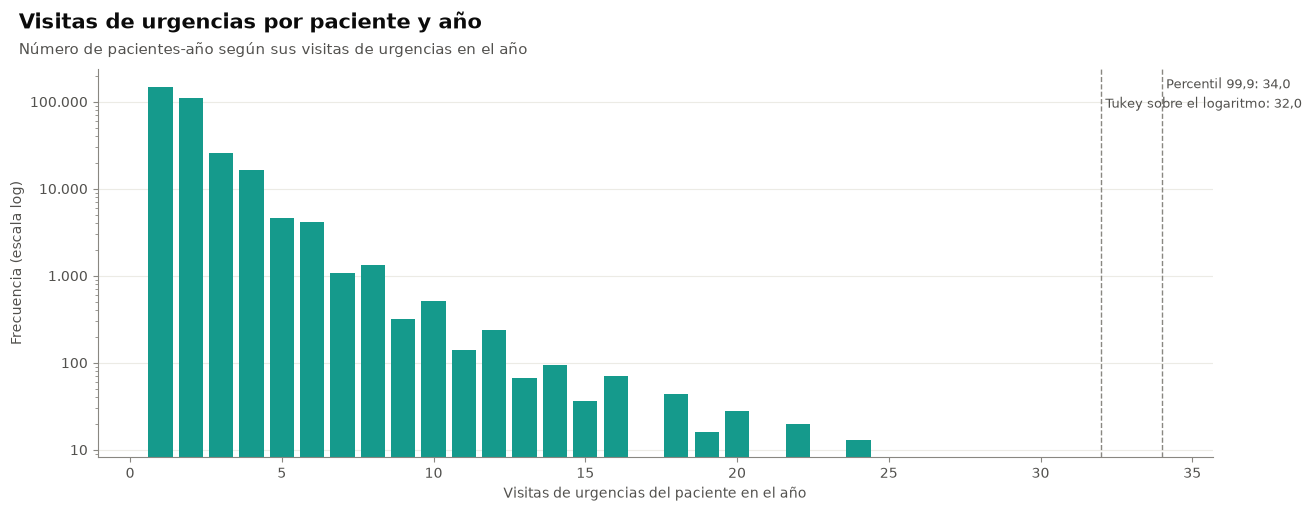

In [33]:
visitas_paciente_anio = conteo_por_paciente_anio(visitas)
anio_llegada = visitas['llegada'].dt.year
una_por_paciente_anio = ~pd.DataFrame({'p': visitas['person_id'], 'a': anio_llegada}).duplicated()
grafico_conteos(visitas_paciente_anio[una_por_paciente_anio].value_counts(),
                limites_usados['paciente_muchas_visitas'], 'Visitas de urgencias por paciente y año',
                'Número de pacientes-año según sus visitas de urgencias en el año',
                '03_visitas_por_paciente_anio', 'Visitas de urgencias del paciente en el año')

## 12. Recorridos idénticos entre pacientes distintos
### Detección

Cada visita de urgencias se resume con una firma de su recorrido: el MD5 de todas sus etapas con tipo, inicio y fin exactos. Se buscan pares de visitas con la misma llegada y la misma firma que pertenecen a 2 pacientes distintos.

### Registros afectados

Pares encontrados, visitas en pares, pares donde solo una visita tiene diagnósticos y visitas que se excluyen.

In [34]:
mostrar_tabla(tabla_segura(resumen_recorridos_identicos(recorridos)),
              'Recorridos idénticos entre pacientes distintos: registros afectados')

**Recorridos idénticos entre pacientes distintos: registros afectados**

,n
medida,
pares de pacientes distintos,5.543
visitas en pares,11.086
pares donde solo una visita tiene diagnósticos,2.690
visitas que se excluyen,2.690


### Distribución

Grupos de visitas con recorrido idéntico por tipo de grupo, comparación de diagnósticos de los pares, perfil de los pares de pacientes distintos y pares por mes de llegada.

In [35]:
recorridos_tipo = consultar('03_recorridos_identicos_tipo').sort_values(
    ['tipo_grupo', 'tramo_etapas', 'coinciden_nacimiento_sexo'])
recorridos_tipo['tipo_grupo'] = recorridos_tipo['tipo_grupo'].str.replace(r'^\d ', '', regex=True)
mostrar_tabla(suprimir_pequenos(recorridos_tipo.set_index(['tipo_grupo', 'tramo_etapas', 'coinciden_nacimiento_sexo']),
                                ['n_grupos', 'n_visitas', 'n_personas']),
              'Grupos de visitas con recorrido idéntico por tipo, tramo de etapas y coincidencia de año de nacimiento y sexo')

recorridos_dx = consultar('03_recorridos_identicos_diagnosticos').sort_values(['tipo_par', 'diagnosticos'])
recorridos_dx = agregar_porcentaje(recorridos_dx, 'n_pares', por='tipo_par')
for columna in ('tipo_par', 'diagnosticos'):
    recorridos_dx[columna] = recorridos_dx[columna].str.replace(r'^\d ', '', regex=True)
mostrar_tabla(suprimir_pequenos(recorridos_dx.set_index(['tipo_par', 'diagnosticos']), ['n_pares']),
              'Pares de visitas con recorrido idéntico por tipo de par y comparación de diagnósticos')

recorridos_perfil = consultar('03_recorridos_identicos_perfil').sort_values(
    ['diferencia_anio_nacimiento', 'menores_de_edad', 'mismo_sexo'])
for columna in ('diferencia_anio_nacimiento', 'menores_de_edad'):
    recorridos_perfil[columna] = recorridos_perfil[columna].str.replace(r'^\d ', '', regex=True)
recorridos_perfil = agregar_porcentaje(recorridos_perfil, 'n_pares')
mostrar_tabla(suprimir_pequenos(recorridos_perfil.set_index(['diferencia_anio_nacimiento', 'menores_de_edad',
                                                             'mismo_sexo']), ['n_pares']),
              'Pares de pacientes distintos por diferencia de año de nacimiento, menores de edad y sexo')

**Grupos de visitas con recorrido idéntico por tipo, tramo de etapas y coincidencia de año de nacimiento y sexo**

n_grupos n_visitas n_personas
tipo_grupo                 tramo_etapas coinciden_nacimiento_sexo                              
mismo paciente             1            True                         9.080    18.176      8.220
                           2-3          True                         8.238    16.501      7.307
                           4+           True                         1.210     2.422      1.157
par de pacientes distintos 1            False                        1.603     3.206      3.013
                                        True                            17        34         30
                           2-3          False                        3.397     6.794      6.156
                                        True                            43        86         66
                           4+           False                          478       956        910
                                        True                           <10        10         10
más de 2 visitas           1            False                           22        67         47
                           2-3          False                           33        99         66
                           4+           False                          <10       <10        <10

**Pares de visitas con recorrido idéntico por tipo de par y comparación de diagnósticos**

n_pares  pct_pares
tipo_par            diagnosticos                             
mismo paciente      ninguna tiene           11.888       64,3
                    solo una tiene           1.842       10,0
                    mismos diagnósticos      4.634       25,1
                    diagnósticos distintos     121        0,7
pacientes distintos ninguna tiene            2.436       43,9
                    solo una tiene           2.690       48,5
                    mismos diagnósticos        <10  suprimido
                    diagnósticos distintos     412        7,4

**Pares de pacientes distintos por diferencia de año de nacimiento, menores de edad y sexo**

n_pares pct_pares
diferencia_anio_nacimiento menores_de_edad mismo_sexo                  
0                          ninguno         False           20       0,4
                                           True            34       0,6
                           ambos           False           19       0,3
                                           True            31       0,6
1-14                       ninguno         False          749      13,5
                                           True           749      13,5
                           uno             False          108       1,9
                                           True            92       1,7
                           ambos           False          118       2,1
                                           True           118       2,1
15-44                      ninguno         False          784      14,1
                                           True           740      13,4
                           uno             False          629      11,3
                                           True           519       9,4
45+                        ninguno         False          192       3,5
                                           True           151       2,7
                           uno             False          228       4,1
                                           True           262       4,7

**Pares de pacientes distintos por mes de llegada**

,n_pares
mes,
2023-01-01,1.226
2023-02-01,164
2023-03-01,191
2023-04-01,144
2023-05-01,204
2023-06-01,183
2023-07-01,207
2023-08-01,162
2023-09-01,145


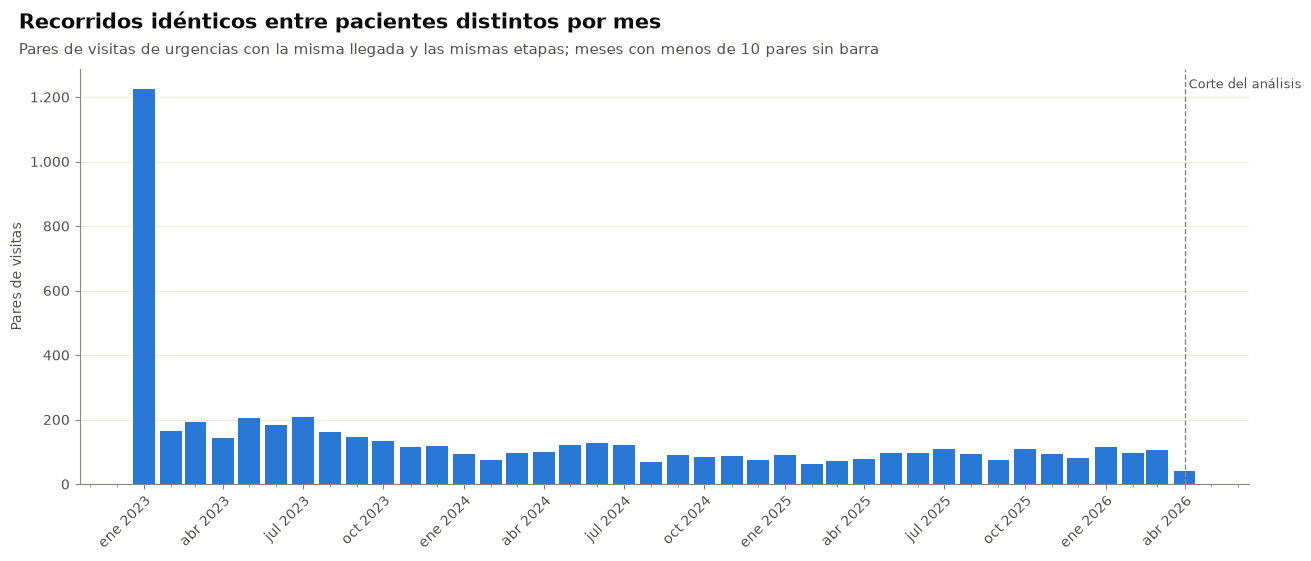

In [36]:
recorridos_mes = consultar('03_recorridos_identicos_mes')
recorridos_mes['mes'] = pd.to_datetime(recorridos_mes['mes'])
recorridos_mes = recorridos_mes.set_index('mes').sort_index()
mostrar_tabla(suprimir_pequenos(recorridos_mes, ['n_pares']), 'Pares de pacientes distintos por mes de llegada')

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(recorridos_mes.index, enmascarar_pequenos(recorridos_mes['n_pares'], recorridos_mes['n_pares']), width=25,
       color=estilo.AZUL)
marcar_corte(ax)
ax.set_ylabel('Pares de visitas')
titulo_hallazgo(fig, 'Recorridos idénticos entre pacientes distintos por mes',
                'Pares de visitas de urgencias con la misma llegada y las mismas etapas; meses con menos de 10 pares sin barra')
guardar_figura(fig, '03_recorridos_identicos_mes')
plt.show()

## 13. Construcción del dataset preliminar
### 13.1 Aplicación de las reglas de registro

Se aplican las acciones de `REGLAS_REGISTRO` a nivel de visita, antes de la fusión en episodios. La tabla muestra cuántas visitas y episodios quita cada regla (en el orden de la configuración).

In [37]:
estado_reglas = pd.DataFrame(
    [{'regla': clave, 'descripcion': regla['descripcion'], 'deteccion': regla['deteccion'],
      'criterio': regla.get('criterio', '—'), 'accion': regla['accion']}
     for clave, regla in config.REGLAS_REGISTRO.items()]
).set_index('regla')
mostrar_tabla(estado_reglas, 'REGLAS_REGISTRO (src/config.py)')

visitas_dataset, reporte_reglas = aplicar_reglas_registro(visitas, marcas, episodio=episodio_visita)
mostrar_tabla(tabla_segura(reporte_reglas, conservar_ceros=True), 'Visitas y episodios quitados por cada regla')
tabla_medidas({
    'visitas antes de aplicar las reglas': len(visitas),
    'visitas después de aplicar las reglas': len(visitas_dataset),
    'visitas quitadas': len(visitas) - len(visitas_dataset),
}, 'Visitas que entran a la construcción de episodios')

**REGLAS_REGISTRO (src/config.py)**

,descripcion,deteccion,criterio,accion
regla,,,,
anio_nacimiento_imposible,Año de nacimiento imposible,year_of_birth < 1900 (incluye el año 1),—,excluir
edad_negativa,Edad negativa,año de llegada − year_of_birth < 0 (con year_of_birth ≥ 1900),—,excluir
edad_mayor_110,Edad mayor a 110,año de llegada − year_of_birth > 110; la edad se conserva (no se pone en NaN),—,conservar
sexo_sin_dato,Sexo sin dato,gender_concept_id = 0 o sin traducción (sexo distinto de FEMALE y MALE),—,conservar
etapas_duracion_0,Etapas de duración 0,la visita tiene al menos una etapa no previa con fin igual al inicio,—,conservar
etapas_duracion_extrema,Etapas de duración extrema,"duración máxima de alguna etapa no previa (9203, 3045729 o 9201) por encima del límite de su tipo de etapa",pendiente,pendiente
fin_fraccion_segundo,Fines de etapa con fracción de segundo,alguna etapa no previa tiene un fin con microsegundos distintos de 0,—,pendiente
hosp_antes_de_llegada,Hospitalización que empieza antes de la llegada,inicio_piso < llegada (dentro de la tolerancia de 1 h),—,excluir
visitas_sin_etapas,Visitas sin etapas,la visita no tiene etapas no previas,—,conservar


**Visitas y episodios quitados por cada regla**

,accion,n_marcadas,n_visitas_quitadas,n_episodios_quitados,n_episodios_modificados
regla,,,,,
anio_nacimiento_imposible,excluir,21,21,19,0
edad_negativa,excluir,<10,<10,<10,0
edad_mayor_110,conservar,<10,0,0,0
sexo_sin_dato,conservar,128,0,0,0
etapas_duracion_0,conservar,362.845,0,0,0
etapas_duracion_extrema,pendiente,NaN,0,0,0
fin_fraccion_segundo,pendiente,507,0,0,0
hosp_antes_de_llegada,excluir,<10,<10,<10,0
visitas_sin_etapas,conservar,54.440,0,0,0


**Visitas que entran a la construcción de episodios**

,medida,valor
0,visitas antes de aplicar las reglas,598.088
1,visitas después de aplicar las reglas,595.375
2,visitas quitadas,2.713


### 13.2 Sensibilidad al umbral de fusión de visitas

Se construyen los episodios con 30, 60 y 120 minutos y se comparan las métricas clave de la población de análisis. Referencia de DBeaver (reglas anteriores): el % > 12 h de hospitalizados cambia menos de 0,1 punto entre umbrales.

In [38]:
sensibilidad = resumen_sensibilidad(visitas_dataset, config.UMBRALES_SENSIBILIDAD)
mostrar_tabla(tabla_segura(sensibilidad), 'Métricas por umbral de fusión')

columna_12h = f'pct_mas_{config.UMBRAL_OPERATIVO_H}h_g3'
variacion_pp = sensibilidad[columna_12h].max() - sensibilidad[columna_12h].min()
tabla_medidas({
    f'variación del % > {config.UMBRAL_OPERATIVO_H} h de hospitalizados entre umbrales (puntos)': fmt_decimal(variacion_pp, 2),
    'referencia de DBeaver (puntos)': f'< {fmt_decimal(config.REFERENCIA_VARIACION_SENSIBILIDAD_PP, 1)}',
}, 'Sensibilidad del % > 12 h de hospitalizados')

**Métricas por umbral de fusión**

,n_episodios,pct_hospitalizados,pct_multivisita,max_visitas_episodio,n_1_contacto_breve,n_2_atencion_urgencias,n_3_hospitalizado,mediana_los_g2_h,pct_mas_12h_g2,mediana_los_g3_h,pct_mas_12h_g3,pct_reconsulta_72h_sin_censura,pct_reconsulta_72h_con_censura
umbral_min,,,,,,,,,,,,,
30,448.720,"7,7","20,8",16,223.707,190.480,34.533,"6,76","27,2","23,95","68,1","7,0","7,0"
60,442.598,"7,8","22,5",16,216.019,192.046,34.533,"6,69","27,0","23,95","68,1","5,7","5,7"
120,439.326,"7,9","23,3",16,211.926,192.867,34.533,"6,65","26,9","23,97","68,1","5,0","5,0"


**Sensibilidad del % > 12 h de hospitalizados**

,medida,valor
0,variación del % > 12 h de hospitalizados entre umbrales (puntos),"0,03"
1,referencia de DBeaver (puntos),"< 0,1"


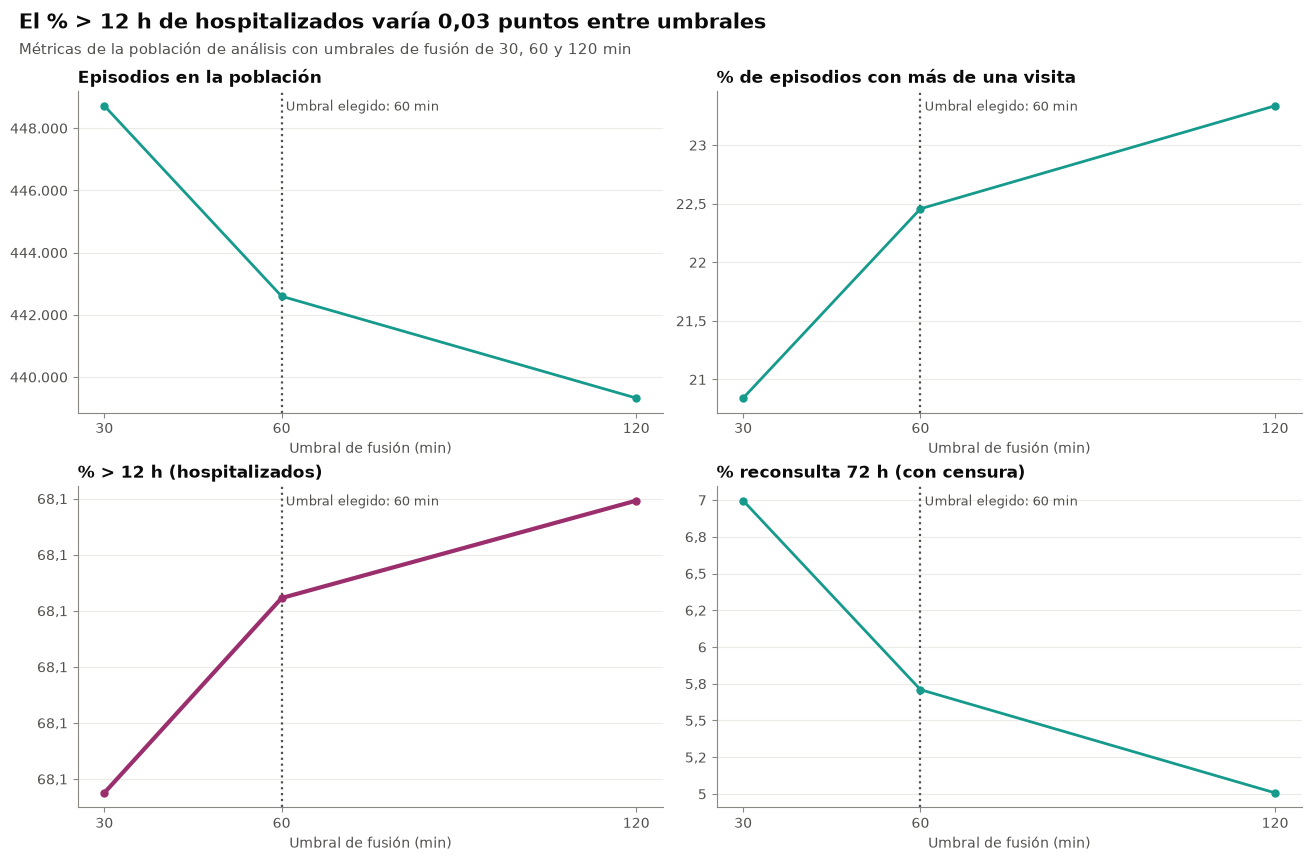

In [39]:
metricas = {
    'n_episodios': 'Episodios en la población',
    'pct_multivisita': '% de episodios con más de una visita',
    columna_12h: f'% > {config.UMBRAL_OPERATIVO_H} h (hospitalizados)',
    'pct_reconsulta_72h_con_censura': '% reconsulta 72 h (con censura)',
}
fig, ejes = plt.subplots(2, 2, figsize=(13, 8.5))
for ax, (columna, titulo) in zip(ejes.ravel(), metricas.items()):
    color = COLOR_HOSP if columna == columna_12h else estilo.VERDE
    ax.plot(sensibilidad.index, sensibilidad[columna], marker='o', color=color,
            linewidth=3 if columna == columna_12h else 2)
    linea_umbral(ax, config.UMBRAL_FUSION_MIN, 'Umbral elegido: 60 min')
    ax.set_xticks(list(sensibilidad.index))
    ax.set_xlabel('Umbral de fusión (min)')
    ax.set_title(titulo)
titulo_hallazgo(fig, f'El % > {config.UMBRAL_OPERATIVO_H} h de hospitalizados varía {fmt_decimal(variacion_pp, 2)} puntos entre umbrales',
                'Métricas de la población de análisis con umbrales de fusión de 30, 60 y 120 min')
guardar_figura(fig, '03_sensibilidad_umbral')
plt.show()

### 13.3 Episodios con el umbral de 60 minutos y comparación con DBeaver

La referencia de DBeaver usó las reglas anteriores: sin visitas sin etapas, sin corte temporal y con otra definición de hospitalizado. `valores_comparables` usa todos los episodios sin corte y excluye los que no tienen etapas. La comparación es informativa.

In [40]:
episodios = construir_episodios(visitas_dataset, config.UMBRAL_FUSION_MIN)

comparacion = pd.DataFrame(
    {
        'referencia_dbeaver': pd.Series(config.REFERENCIA_SQL_60MIN, dtype=float),
        'reglas_nuevas': pd.Series(valores_comparables(episodios), dtype=float),
    }
).rename_axis('metrica')
comparacion['diferencia'] = comparacion['reglas_nuevas'] - comparacion['referencia_dbeaver']
mostrar_tabla(suprimir_pequenos(comparacion.round(2), []), 'Comparación con la referencia de DBeaver')

**Comparación con la referencia de DBeaver**

,referencia_dbeaver,reglas_nuevas,diferencia
metrica,,,
episodios,440.202,437.522,-2.680
hosp_con_hora_piso,36.382,36.260,-122
mediana_los_hosp_h,24,"24,01","0,01"
pct_mas_12h_hosp,"68,20","68,13","-0,07"
pct_mas_24h_hosp,50,"50,01","0,01"
mediana_los_atencion_h,7,"6,71","-0,29"
pct_mas_12h_atencion,28,"27,26","-0,74"
pct_reconsulta_72h,"5,40","5,66","0,26"


### 13.4 Tamaño de los tres grupos y casos con LOS recortado a 0

In [41]:
fuera = episodios['en_poblacion'].map({True: 'en_poblacion', False: 'fuera_de_poblacion'}).value_counts()
mostrar_tabla(suprimir_pequenos(fuera.rename('n_episodios').rename_axis('alcance').to_frame(), ['n_episodios']),
              'Episodios dentro y fuera de la población de análisis')

poblacion = episodios[episodios['en_poblacion']]
tamano_grupos = (
    poblacion['grupo'].value_counts()
    .reindex(list(config.GRUPOS), fill_value=0)
    .rename_axis('grupo')
    .rename('n_episodios')
    .to_frame()
)
tamano_grupos = agregar_porcentaje(tamano_grupos, 'n_episodios')
tamano_grupos['n_sin_etapas'] = poblacion.groupby('grupo')['sin_etapas'].sum().reindex(tamano_grupos.index, fill_value=0)
tamano_grupos['n_multivisita'] = poblacion['n_visitas'].gt(1).groupby(poblacion['grupo']).sum().reindex(tamano_grupos.index, fill_value=0)
mostrar_tabla(tabla_segura(tamano_grupos), 'Tamaño de los grupos (población de análisis)')

mostrar_tabla(tabla_segura(contar_los_recortados(poblacion)), 'Hospitalizados con LOS recortado a 0')

**Episodios dentro y fuera de la población de análisis**

,n_episodios
alcance,
en_poblacion,442.598
fuera_de_poblacion,25.952


**Tamaño de los grupos (población de análisis)**

,n_episodios,pct_episodios,n_sin_etapas,n_multivisita
grupo,,,,
1_contacto_breve,216.019,"48,8",26.702,27.069
2_atencion_urgencias,192.046,"43,4",<10,61.822
3_hospitalizado,34.533,"7,8",<10,10.504


**Hospitalizados con LOS recortado a 0**

,n,n_recortados,pct_recortados
grupo,,,
3_hospitalizado,34.533,<10,suprimido


**Episodios por mes y grupo (todos los meses)**

grupo,1_contacto_breve,2_atencion_urgencias,3_hospitalizado
mes,,,
2023-01-01,6.853,4.826,978
2023-02-01,6.114,4.506,855
2023-03-01,7.161,5.501,990
2023-04-01,6.994,4.864,1.001
2023-05-01,8.350,5.332,995
2023-06-01,7.117,5.174,964
2023-07-01,6.995,5.231,978
2023-08-01,6.852,5.244,997
2023-09-01,6.130,5.045,896


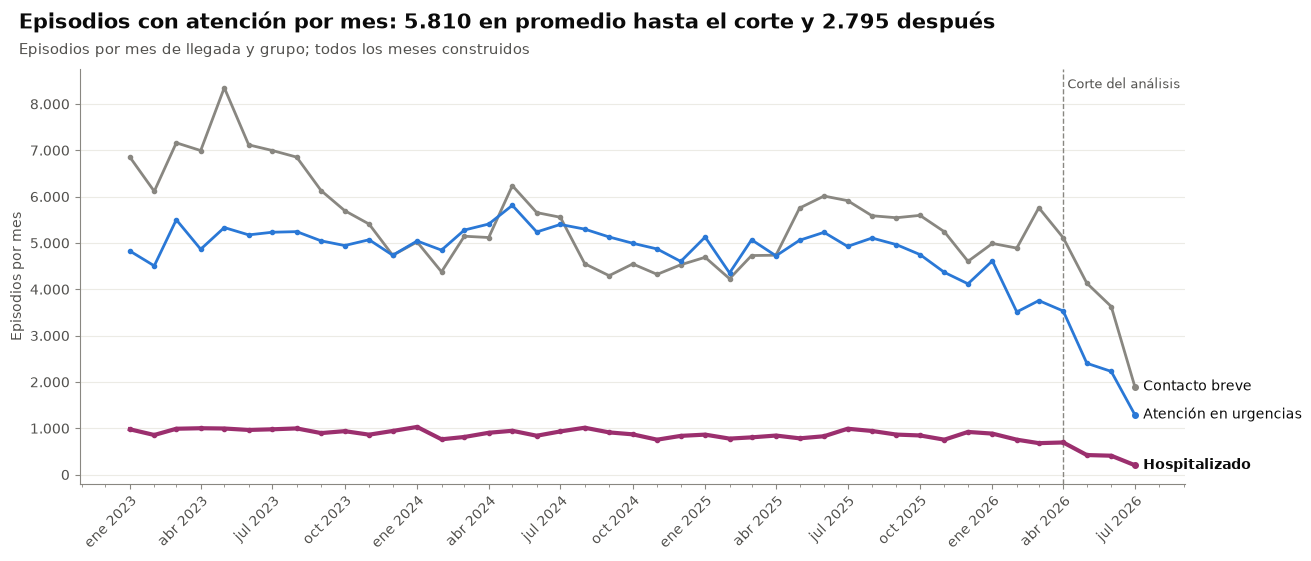

In [42]:
por_mes_grupo = (
    episodios.assign(mes=episodios['llegada'].dt.to_period('M').dt.to_timestamp())
    .groupby(['mes', 'grupo']).size()
    .unstack('grupo', fill_value=0)
    .reindex(columns=list(config.GRUPOS), fill_value=0)
)
mostrar_tabla(suprimir_pequenos(por_mes_grupo, list(por_mes_grupo.columns)), 'Episodios por mes y grupo (todos los meses)')

fig, ax = plt.subplots(figsize=(13, 5.5))
for grupo in config.GRUPOS:
    valores = enmascarar_pequenos(por_mes_grupo[grupo], por_mes_grupo[grupo])
    ax.plot(valores.index, valores, marker='o', markersize=3, color=COLORES_GRUPO[grupo], linewidth=ancho_linea(grupo))
    etiquetas_directas(ax, valores.index, {ETIQUETAS_CORTAS_GRUPO[grupo]: (valores, COLORES_GRUPO[grupo])},
                       negrita=[ETIQUETAS_CORTAS_GRUPO[G3]])
marcar_corte(ax)
ax.set_ylabel('Episodios por mes')
con_atencion = por_mes_grupo[[G2, G3]].sum(axis=1)
antes = con_atencion[con_atencion.index <= config.FECHA_CORTE_ANALISIS]
despues = con_atencion[con_atencion.index > config.FECHA_CORTE_ANALISIS]
if not despues.empty:
    titulo = (f'Episodios con atención por mes: {fmt_entero(antes.mean())} en promedio hasta el corte '
              f'y {fmt_entero(despues.mean())} después')
else:
    titulo = 'Episodios de urgencias por mes y grupo'
titulo_hallazgo(fig, titulo, 'Episodios por mes de llegada y grupo; todos los meses construidos')
guardar_figura(fig, '03_episodios_mes_grupo')
plt.show()

## 14. Exportación del dataset preliminar

Se guardan `data/interim/episodios_preliminar_60min.parquet` (con identificadores internos; solo en `data/interim/`, ignorado por git) y su `.json` de metadatos. Las columnas se describen en `docs/diccionario_episodios.md`.

In [43]:
nombre_base = f'episodios_preliminar_{config.UMBRAL_FUSION_MIN}min'
config.DATA_INTERIM.mkdir(parents=True, exist_ok=True)
episodios.to_parquet(config.DATA_INTERIM / f'{nombre_base}.parquet', index=False)

metadatos = {
    'dataset': 'preliminar',
    'umbral_fusion_min': config.UMBRAL_FUSION_MIN,
    'fecha_ejecucion': datetime.now().isoformat(timespec='seconds'),
    'n_filas': int(len(episodios)),
    'n_filas_en_poblacion': int(episodios['en_poblacion'].sum()),
    'n_filas_por_grupo': {g: int(n) for g, n in episodios['grupo'].value_counts().items()},
    'n_filas_por_grupo_en_poblacion': {g: int(n) for g, n in tamano_grupos['n_episodios'].items()},
    'fecha_inicio_analisis': str(config.FECHA_INICIO_ANALISIS),
    'fecha_corte_analisis': str(config.FECHA_CORTE_ANALISIS),
    'sql': 'sql/visitas_urgencias.sql',
    'sha256_sql': hash_sql('visitas_urgencias'),
    'n_visitas_antes_de_reglas': int(len(visitas)),
    'n_visitas_despues_de_reglas': int(len(visitas_dataset)),
    'reglas_registro': {
        clave: {
            'accion': regla['accion'],
            'criterio': regla.get('criterio'),
            'n_visitas_quitadas': int(reporte_reglas.loc[clave, 'n_visitas_quitadas']),
            'n_episodios_quitados': (None if pd.isna(reporte_reglas.loc[clave, 'n_episodios_quitados'])
                                     else int(reporte_reglas.loc[clave, 'n_episodios_quitados'])),
        }
        for clave, regla in config.REGLAS_REGISTRO.items()
    },
    'recorridos_identicos_otro_paciente': {
        'sql': 'sql/03_recorridos_identicos_marcas.sql',
        'sha256_sql': hash_sql('03_recorridos_identicos_marcas'),
        **{medida: int(n) for medida, n in resumen_recorridos_identicos(recorridos)['n'].items()},
    },
    'ventanas_reconsulta': list(config.VENTANAS_RECONSULTA),
    'umbrales_los_h': config.UMBRALES_LOS_H,
}
with open(config.DATA_INTERIM / f'{nombre_base}.json', 'w', encoding='utf-8') as archivo:
    json.dump(metadatos, archivo, ensure_ascii=False, indent=2)
tabla_medidas({'parquet': f'data/interim/{nombre_base}.parquet', 'metadatos': f'data/interim/{nombre_base}.json',
               'filas': len(episodios), 'columnas': episodios.shape[1]}, 'Archivos exportados')

**Archivos exportados**

,medida,valor
0,parquet,data/interim/episodios_preliminar_60min.parquet
1,metadatos,data/interim/episodios_preliminar_60min.json
2,filas,468.550
3,columnas,42
